# Bosch Production Line Performance

Задача исследования - изучить производственные измерения и определить особенности данных, влияющие на настройку AutoML для выявления дефектов. Целевая переменная `Response`: 1 - брак, 0 - отсутствие брака.

Источник: [Bosch Production Line Performance (Kaggle)](https://www.kaggle.com/competitions/bosch-production-line-performance/data). Расчёты и выводы представлены в `EDA_bosch_production_line_performance.md`.

Шесть архивов [train_numeric.csv.zip](https://drive.google.com/file/d/1Sb0kv9H5GjVCigntyBgdTp7oBizIlNXD/view?usp=drive_link), [train_categorical.csv.zip](https://drive.google.com/file/d/1I7vgDIJgykCK2rgjE23091kp5kQAEr4O/view?usp=drive_link), [train_date.csv.zip](https://drive.google.com/file/d/1Ag6xtJ-dfXRlw_V9-g4v1Rm_Zwso7eDJ/view?usp=drive_link), [test_numeric.csv.zip](https://drive.google.com/file/d/1cgtSjpzVwpoztJ48yEwZWfPtQ0wPRDXh/view?usp=drive_link), [test_categorical.csv.zip](https://drive.google.com/file/d/1xsE3eSdL1W6AIBqXpQJU2fxn2ZT7aSUo/view?usp=drive_link), [test_date.csv.zip](https://drive.google.com/file/d/1Y7c3RrMKsT_jtS8AbiHz4-1QKvrzaJc0/view?usp=drive_link) размещаются рядом с ноутбуком. Ячейки выполняются последовательно.

## 1. Первичный анализ

Проверяются состав файлов, размеры таблиц и соответствие признаков. Целевая переменная `Response` содержится в `train_numeric`.

In [1]:
import re
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

names = ["train_numeric", "train_categorical", "train_date",
         "test_numeric", "test_categorical", "test_date"]
files = {}
for name in names:
    files[name] = Path(f"{name}.csv.zip")

print(pd.Series(files, name="Файл"))
assert all(path.exists() for path in files.values()), "Не найдены исходные файлы"

train_numeric            train_numeric.csv.zip
train_categorical    train_categorical.csv.zip
train_date                  train_date.csv.zip
test_numeric              test_numeric.csv.zip
test_categorical      test_categorical.csv.zip
test_date                    test_date.csv.zip
Name: Файл, dtype: object


In [2]:
columns = {name: pd.read_csv(path, nrows=0).columns.tolist()
           for name, path in files.items()}
for name in names:
    print(name, "- столбцов:", len(columns[name]))

print("Таргет в train_numeric:", "Response" in columns["train_numeric"])
print("Таргет в test_numeric:", "Response" in columns["test_numeric"])

train_numeric - столбцов: 970
train_categorical - столбцов: 2141
train_date - столбцов: 1157
test_numeric - столбцов: 969
test_categorical - столбцов: 2141
test_date - столбцов: 1157
Таргет в train_numeric: True
Таргет в test_numeric: False


In [3]:
target = pd.read_csv(files["train_numeric"], usecols=["Id", "Response"])
test_ids = pd.read_csv(files["test_numeric"], usecols=["Id"])
print("Train:", target.shape, "Test:", test_ids.shape)
print("Повторы Id в train:", target["Id"].duplicated().sum())
print("Повторы Id в test:", test_ids["Id"].duplicated().sum())
print("Пересечения Id train/test:", target["Id"].isin(test_ids["Id"]).sum())
display(target.head())

Train: (1183747, 2) Test: (1183748, 1)
Повторы Id в train: 0
Повторы Id в test: 0
Пересечения Id train/test: 0


,Id,Response
0,4,0
1,6,0
2,7,0
3,9,0
4,11,0


In [4]:
for name in ["train_categorical", "train_date", "test_categorical", "test_date"]:
    ids = pd.read_csv(files[name], usecols=["Id"])["Id"]
    reference = target["Id"] if name.startswith("train") else test_ids["Id"]
    print(name, "строк:", len(ids),
          "повторов Id:", ids.duplicated().sum(),
          "совпадает порядок Id:", ids.equals(reference))

train_categorical строк: 1183747 повторов Id: 0 совпадает порядок Id: True
train_date строк: 1183747 повторов Id: 0 совпадает порядок Id: True
test_categorical строк: 1183748 повторов Id: 0 совпадает порядок Id: True
test_date строк: 1183748 повторов Id: 0 совпадает порядок Id: True


## 2. Распределение целевой переменной

Определяются число дефектных деталей и доля положительного класса. Общая accuracy не отражает качество обнаружения редких дефектов.

,Количество,"Доля, %"
Response,,
0,1176868,99.419
1,6879,0.581


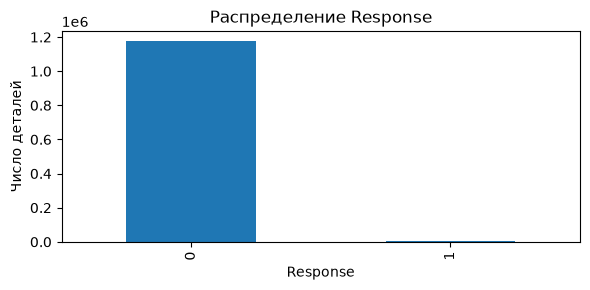

In [5]:
counts = target["Response"].value_counts(dropna=False).sort_index()
display(pd.DataFrame({"Количество": counts,
                      "Доля, %": (100 * counts / len(target)).round(3)}))
counts.plot.bar(figsize=(6, 3), title="Распределение Response")
plt.xlabel("Response")
plt.ylabel("Число деталей")
plt.tight_layout()
plt.show()

## 3. Пропуски и структура признаков

Проверяются пропуски по всем столбцам, доля полностью пустых признаков и различия между группами `numeric`, `categorical`, `date`. Отсутствие измерения может отражать производственный маршрут детали.

In [6]:
missing = {}
row_counts = {}
samples = {}
for name in ["train_numeric", "train_categorical", "train_date"]:
    empty_counts = pd.Series(0, index=columns[name], dtype="int64")
    n = 0
    sample_parts = []
    for i, part in enumerate(pd.read_csv(files[name], chunksize=10000, low_memory=False)):
        empty_counts += part.isna().sum()
        n += len(part)
        if name != "train_date":
            sample_parts.append(part.sample(n=min(len(part), 25), random_state=42 + i))
    if sample_parts:
        samples[name] = pd.concat(sample_parts, ignore_index=True)
    missing[name] = 100 * empty_counts / n
    row_counts[name] = n
    print(name, "строк:", n,
          "полностью пустых признаков:", (empty_counts == n).sum(),
          "признаков с >50% пропусков:", (missing[name] > 50).sum())

train_numeric строк: 1183747 полностью пустых признаков: 0 признаков с >50% пропусков: 812
train_categorical строк: 1183747 полностью пустых признаков: 163 признаков с >50% пропусков: 2077
train_date строк: 1183747 полностью пустых признаков: 0 признаков с >50% пропусков: 986


In [7]:
for name in ["train_numeric", "train_categorical", "train_date"]:
    print()
    print(name)
    display(missing[name].sort_values(ascending=False).head(12).round(2).to_frame("Пропуски, %"))
    print("Полностью пустые:", missing[name][missing[name] == 100].index.tolist()[:20])


train_numeric


,"Пропуски, %"
L1_S25_F2181,99.89
L1_S25_F2193,99.89
L1_S25_F2187,99.89
L1_S25_F2184,99.89
L1_S25_F2190,99.89
L1_S25_F2196,99.89
L1_S25_F2199,99.89
L1_S25_F2202,99.89
L1_S25_F2724,99.82
L1_S25_F2722,99.82


Полностью пустые: []

train_categorical


,"Пропуски, %"
L3_S47_F4189,100.0
L0_S3_F77,100.0
L3_S47_F4192,100.0
L0_S3_F69,100.0
L3_S47_F4187,100.0
L3_S47_F4184,100.0
L1_S24_F1157,100.0
L1_S24_F1159,100.0
L1_S24_F1160,100.0
L3_S47_F4167,100.0


Полностью пустые: ['L0_S3_F69', 'L0_S3_F71', 'L0_S3_F73', 'L0_S3_F75', 'L0_S3_F77', 'L0_S3_F79', 'L0_S3_F81', 'L0_S3_F83', 'L0_S3_F85', 'L0_S3_F87', 'L0_S3_F89', 'L0_S3_F91', 'L0_S3_F93', 'L0_S3_F95', 'L0_S3_F97', 'L0_S3_F99', 'L0_S3_F101', 'L0_S3_F103', 'L0_S18_F436', 'L0_S18_F438']

train_date


,"Пропуски, %"
L1_S24_D1158,100.00
L3_S46_D4135,100.00
L3_S42_D4049,100.00
L3_S42_D4057,100.00
L3_S42_D4053,100.00
L3_S42_D4045,100.00
L3_S42_D4033,100.00
L3_S42_D4029,100.00
L3_S42_D4037,100.00
L3_S42_D4041,100.00


Полностью пустые: []


,Столбцов,Средний % пропусков,Пустые столбцы,>50% пропусков
train_numeric,970,80.92,0,812
train_categorical,2141,97.28,163,2077
train_date,1157,82.17,0,986


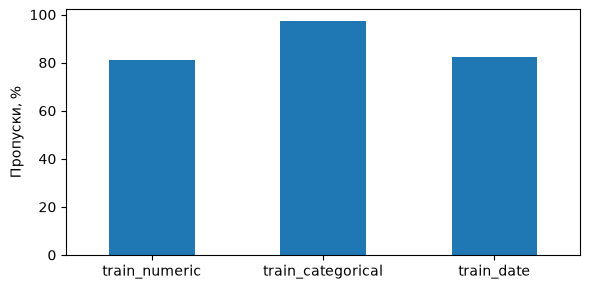

In [8]:
summary_missing = pd.DataFrame({
    "Столбцов": [len(columns[name]) for name in missing],
    "Средний % пропусков": [missing[name].mean() for name in missing],
    "Пустые столбцы": [(missing[name] == 100).sum() for name in missing],
    ">50% пропусков": [(missing[name] > 50).sum() for name in missing]
}, index=list(missing))
display(summary_missing.round(2))

summary_missing["Средний % пропусков"].plot.bar(figsize=(6, 3))
plt.ylabel("Пропуски, %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [9]:
sample_numeric = samples["train_numeric"]
sample_categorical = samples["train_categorical"]
sample_date = pd.read_csv(files["train_date"], nrows=5000)

for name, frame in [("numeric", sample_numeric),
                    ("categorical", sample_categorical), ("date", sample_date)]:
    n_unique = frame.drop(columns=["Id", "Response"], errors="ignore").nunique(dropna=True)
    print(name, "признаков с одним непустым значением в проверенной части:",
          (n_unique == 1).sum())

numeric признаков с одним непустым значением в проверенной части: 47
categorical признаков с одним непустым значением в проверенной части: 644
date признаков с одним непустым значением в проверенной части: 0


## 4. Производственные линии, станции и маршруты

Названия признаков вида `L*_S*_F*` содержат обозначения производственной линии и станции. Проверяются число групп, неполнота измерений по станциям и связь факта измерения с целевой переменной. Эти зависимости не доказывают причинное влияние конкретной станции.

In [10]:
stations = {}
for col in columns["train_numeric"]:
    match = re.match(r"^(L\d+_S\d+)_", col)
    if match:
        stations.setdefault(match.group(1), []).append(col)
print("Станций в числовых признаках:", len(stations))
display(pd.Series({k: len(v) for k, v in stations.items()})
        .sort_values(ascending=False).head(12).to_frame("Признаков"))

Станций в числовых признаках: 50


,Признаков
L1_S25,284
L1_S24,229
L3_S30,68
L3_S29,53
L2_S27,14
L0_S22,14
L0_S23,14
L0_S21,14
L2_S26,14
L2_S28,14


,"Покрытие, %"
L3_S37,94.86
L3_S29,94.82
L3_S30,94.72
L3_S33,94.69
L3_S34,94.59
L0_S1,57.45
L0_S8,57.45
L0_S0,57.41
L3_S36,47.60
L3_S35,47.39


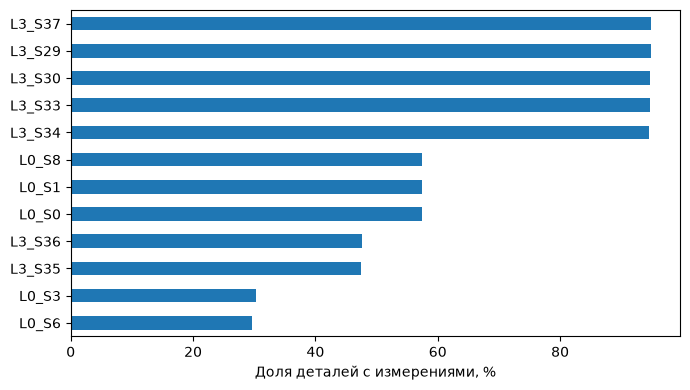

In [11]:
station_presence = pd.DataFrame({"Response": sample_numeric["Response"]})
for station, cols in stations.items():
    station_presence[station] = sample_numeric[cols].notna().any(axis=1)
station_coverage = station_presence.drop(columns="Response").mean().sort_values(ascending=False)
selected_stations = station_coverage.head(8).index.tolist()
display((100 * station_coverage.head(12)).round(2).to_frame("Покрытие, %"))

(100 * station_coverage.head(12).sort_values()).plot.barh(figsize=(7, 4))
plt.xlabel("Доля деталей с измерениями, %")
plt.tight_layout()
plt.show()


In [12]:
station_results = []
for station in selected_stations:
    for observed in [False, True]:
        mask = station_presence[station] == observed
        if mask.sum():
            station_results.append([station, observed, int(mask.sum()),
                                    100 * station_presence.loc[mask, "Response"].mean()])
station_result = pd.DataFrame(station_results,
                              columns=["Станция", "Есть измерения", "Объектов", "Доля брака, %"])
display(station_result.round(3))

,Станция,Есть измерения,Объектов,"Доля брака, %"
0,L3_S37,False,153,1.307
1,L3_S37,True,2822,0.567
2,L3_S29,False,154,1.299
3,L3_S29,True,2821,0.567
4,L3_S30,False,157,1.274
5,L3_S30,True,2818,0.568
6,L3_S33,False,158,1.899
7,L3_S33,True,2817,0.532
8,L3_S34,False,161,1.863
9,L3_S34,True,2814,0.533


## 5. Категории, числовые признаки и аномалии

Проверяется разнообразие категорий, числовые распределения и возможные нетипичные значения. Подробные графики строятся для нескольких признаков, выбранных по заполненности и разнообразию значений.

In [13]:
cat_columns = sample_categorical.drop(columns="Id").nunique(dropna=True)
print("Категориальных признаков:", len(cat_columns))
display(cat_columns.describe().round(2).to_frame("Число категорий"))
display(cat_columns.sort_values(ascending=False).head(10).to_frame("Категорий"))

Категориальных признаков: 2140


,Число категорий
count,2140.00
mean,0.33
std,0.58
min,0.00
25%,0.00
50%,0.00
75%,1.00
max,13.00


,Категорий
L3_S32_F3854,13
L1_S25_F1852,5
L1_S25_F2229,4
L1_S24_F1525,4
L1_S25_F2779,3
L1_S24_F1510,3
L1_S24_F1530,3
L2_S26_F3099,2
L1_S24_F710,2
L2_S27_F3192,2


Признаки для графиков: ['L0_S0_F0', 'L0_S0_F2', 'L0_S0_F4', 'L0_S0_F6']


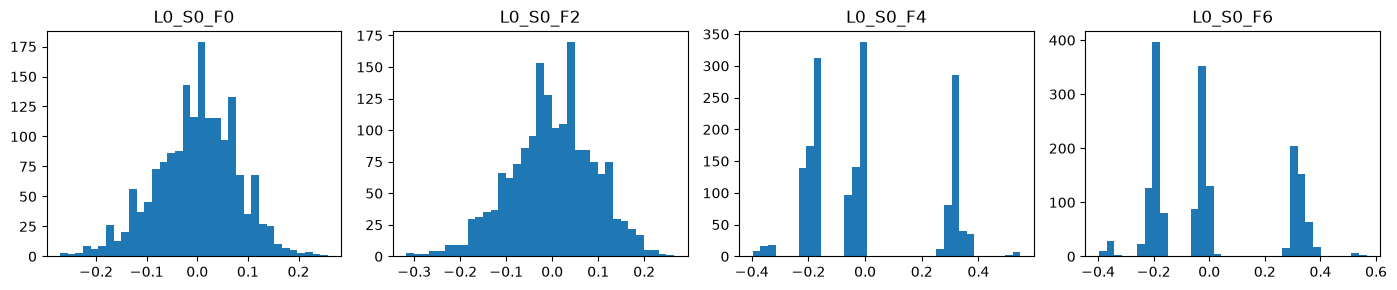

In [14]:
numeric_names = [c for c in sample_numeric.columns if c not in ["Id", "Response"]]
valid_numeric = sample_numeric[numeric_names].select_dtypes(include="number")
selected_numeric = [c for c in valid_numeric.columns
                    if valid_numeric[c].notna().mean() > 0.2
                    and valid_numeric[c].nunique(dropna=True) > 10][:4]
print("Признаки для графиков:", selected_numeric)
if selected_numeric:
    fig, axes = plt.subplots(1, len(selected_numeric), figsize=(3.5 * len(selected_numeric), 3))
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, selected_numeric):
        ax.hist(sample_numeric[col].dropna(), bins=35)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

In [15]:
print("Пропущенные значения Response:", target["Response"].isna().sum())
print("Необычные метки Response:", sorted(set(target["Response"].dropna()) - {0, 1}))

if selected_numeric:
    display(sample_numeric.groupby("Response")[selected_numeric].median().round(3))

Пропущенные значения Response: 0
Необычные метки Response: []


,L0_S0_F0,L0_S0_F2,L0_S0_F4,L0_S0_F6
Response,,,,
0,0.003,0.004,-0.033,-0.034
1,0.007,-0.011,-0.161,-0.161


## 6. Временная структура и неоднородность брака

В `train_date` временные значения связаны с прохождением производственных этапов. Для каждой детали определяется первое и последнее доступное время измерения. Далее исследуется частота брака в последовательных временных группах.

In [16]:
date_parts = []
for part in pd.read_csv(files["train_date"], chunksize=10000, low_memory=False):
    values = part.drop(columns="Id")
    date_parts.append(pd.DataFrame({
        "Id": part["Id"].to_numpy(),
        "first_time": values.min(axis=1).to_numpy(),
        "last_time": values.max(axis=1).to_numpy(),
        "date_features": values.notna().sum(axis=1).to_numpy()
    }))
part_times = pd.concat(date_parts, ignore_index=True)
print("Деталей без временных измерений:", part_times["first_time"].isna().sum())
display(part_times[["first_time", "last_time", "date_features"]].describe().round(3))

Деталей без временных измерений: 582


,first_time,last_time,date_features
count,1183165.000,1183165.000,1183747.000
mean,848.415,859.133,205.264
std,468.974,468.339,32.131
min,0.000,0.460,0.000
25%,466.820,491.360,178.000
50%,877.710,887.390,207.000
75%,1238.140,1240.360,233.000
max,1716.540,1718.480,399.000


In [17]:
time_target = target.merge(part_times, on="Id", how="left", validate="one_to_one")
known_time = time_target.dropna(subset=["first_time"]).copy()
known_time["period"] = pd.qcut(known_time["first_time"], q=8, duplicates="drop")
by_period = known_time.groupby("period", observed=True)["Response"].agg(["size", "mean"])
by_period["Доля брака, %"] = (100 * by_period["mean"]).round(3)
display(by_period[["size", "Доля брака, %"]])

,size,"Доля брака, %"
period,,
"(-0.001, 237.96]",147897,0.516
"(237.96, 466.82]",147897,0.821
"(466.82, 672.45]",147932,0.605
"(672.45, 877.71]",147863,1.020
"(877.71, 1023.94]",147900,0.620
"(1023.94, 1238.14]",147885,0.239
"(1238.14, 1433.51]",147897,0.435
"(1433.51, 1716.54]",147894,0.394


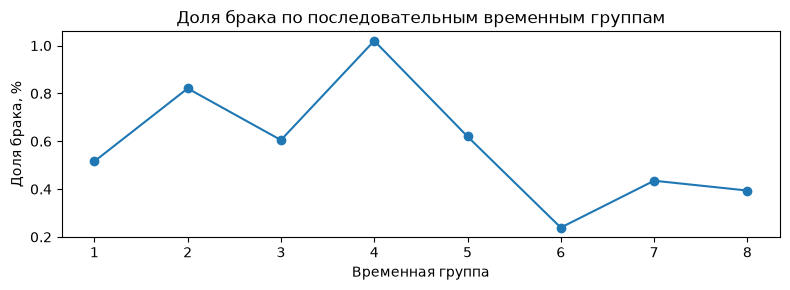

In [18]:
by_period["Доля брака, %"].plot(marker="o", figsize=(8, 3))
plt.title("Доля брака по последовательным временным группам")
plt.xlabel("Временная группа")
plt.ylabel("Доля брака, %")
plt.xticks(range(len(by_period)), [str(i + 1) for i in range(len(by_period))])
plt.tight_layout()
plt.show()

Измеренные интервалы (last_time - first_time):
count    1183165.000
mean          10.718
std           17.015
min            0.000
50%            3.700
90%           35.200
99%           62.950
max          699.200
dtype: float64
Первое время > последнего: 0


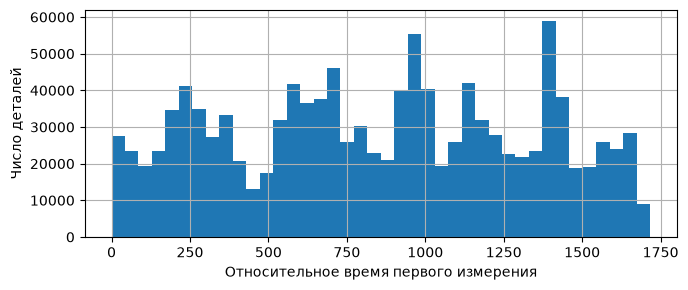

In [19]:
print("Измеренные интервалы (last_time - first_time):")
print((part_times["last_time"] - part_times["first_time"])
      .describe(percentiles=[0.5, 0.9, 0.99]).round(3))
print("Первое время > последнего:",
      (part_times["first_time"] > part_times["last_time"]).sum())

part_times["first_time"].dropna().hist(bins=40, figsize=(7, 3))
plt.xlabel("Относительное время первого измерения")
plt.ylabel("Число деталей")
plt.tight_layout()
plt.show()


## 7. Сравнение train/test

Проверяются совпадение наборов столбцов и различия заполненности характерных признаков. Сравнение неразмеченного test служит для проверки распределений, а не для расчёта качества модели.

In [20]:
for kind in ["numeric", "categorical", "date"]:
    train_cols = set(columns[f"train_{kind}"]) - {"Response"}
    test_cols = set(columns[f"test_{kind}"])
    print(kind, "только train:", len(train_cols - test_cols),
          "только test:", len(test_cols - train_cols))

numeric только train: 0 только test: 0
categorical только train: 0 только test: 0
date только train: 0 только test: 0


In [22]:
check_features = {}
for name in missing:
    values = missing[name].drop(labels=["Id", "Response"], errors="ignore").sort_values()
    indices = [0, len(values) // 4, len(values) // 2,
               3 * len(values) // 4, len(values) - 2, len(values) - 1]
    check_features[name] = list(dict.fromkeys(values.index[indices]))

for name, selected in check_features.items():
    test_name = name.replace("train_", "test_")
    keep = [c for c in selected if c in columns[test_name]]
    dtype = "string" if name == "train_categorical" else None

    train_part = pd.read_csv(files[name], usecols=keep, dtype=dtype)
    test_part = pd.read_csv(files[test_name], usecols=keep, dtype=dtype)
    comp = pd.DataFrame({"train, %": 100 * train_part.isna().mean(),
                         "test, %": 100 * test_part.isna().mean()}).round(2)
    print(name)
    display(comp)

train_numeric


,"train, %","test, %"
L0_S9_F155,80.94,80.93
L1_S24_F1026,98.99,99.00
L1_S25_F1865,95.33,95.32
L1_S25_F2181,99.89,99.90
L1_S25_F2184,99.89,99.90
L3_S37_F3944,5.35,5.36


train_categorical


,"train, %","test, %"
L0_S9_F159,99.96,99.96
L0_S11_F313,100.00,100.00
L1_S24_F1239,100.00,100.00
L1_S24_F1561,100.00,100.00
L1_S24_F1563,100.00,100.00
L3_S29_F3317,33.65,33.62


train_date


,"train, %","test, %"
L0_S10_D236,81.03,81.00
L1_S24_D1001,99.00,98.99
L1_S24_D1158,100.00,100.00
L1_S25_D2172,95.35,95.35
L3_S37_D3951,5.35,5.36
L3_S46_D4135,100.00,100.00


## 8. Связи признаков с целевой переменной

Для выбранных измерений сравниваются распределения у деталей разных классов. Наличие связи не доказывает, что признак был доступен до решения о качестве детали.

In [23]:
if selected_numeric:
    correlations = sample_numeric[["Response"] + selected_numeric].corr(numeric_only=True)
    display(correlations["Response"].drop("Response").sort_values(ascending=False).round(3))

L0_S0_F2    0.010
L0_S0_F0    0.006
L0_S0_F4   -0.004
L0_S0_F6   -0.008
Name: Response, dtype: float64

In [24]:
print("Наличие измерений в отобранных станциях и средняя частота брака:")
display(station_result.sort_values(["Станция", "Есть измерения"]).round(3))

Наличие измерений в отобранных станциях и средняя частота брака:


,Станция,Есть измерения,Объектов,"Доля брака, %"
14,L0_S0,False,1267,0.631
15,L0_S0,True,1708,0.585
10,L0_S1,False,1266,0.632
11,L0_S1,True,1709,0.585
12,L0_S8,False,1266,0.632
13,L0_S8,True,1709,0.585
2,L3_S29,False,154,1.299
3,L3_S29,True,2821,0.567
4,L3_S30,False,157,1.274
5,L3_S30,True,2818,0.568


## 9. Потенциальные утечки и ограничения

Наличие или отсутствие измерений может характеризовать производственный маршрут детали. Это свойство требует проверки на предмет зависимости от того, на каком этапе предполагается прогнозирование.

Поля времени и измерений разных станций не могут считаться допустимыми признаками без уточнения момента прогнозирования. По одним только анонимизированным данным нельзя доказать наличие утечки или причинное влияние станции на брак.

## 10. Ожидаемые действия AutoML-агента

1. Сопоставить прикладную задачу с `Response` и бинарной классификацией.
2. Учитывать редкий положительный класс и стоимость ошибок при выборе метрики.
3. Анализировать структуру пропусков, не удалять разреженные признаки автоматически.
4. Проверять соответствие ключей `Id` между числовыми, категориальными и временными таблицами.
5. Учитывать временную неоднородность при выборе внешнего разбиения.
6. Проверять доступность измерений к моменту прогноза и различать гипотезы об утечке с доказанными случаями.
7. Учитывать многочисленные признаки и изменения заполненности train/test.